# 02 · Data audit: can the warehouse be trusted for modelling?

## What this notebook is, and where it sits in the project

The project builds two things on Bondora's public loan data:

* **Track A, a credit scorecard.** A model that looks at a loan application and estimates the probability that the borrower defaults within 12 months (the *PD*).
* **Track B, an IFRS 9 engine.** Uses PDs, recoveries and exposures to estimate how much money a lender should set aside for expected losses (*ECL*), including under stressed economic scenarios.

Both rest on the data. Notebook 01 looked at what the two sources contain and showed that every Kaggle loan can be joined to the official feed. The warehouse (`python -m pdengine.warehouse`) then loaded both into one DuckDB database, `data/bondora.duckdb`.

**A data audit** is the step a bank's model validation team would insist on before any model is built: prove that the data are the right version, that they pass basic quality rules, that no column secretly contains the answer, and that the target (the thing we predict) means what we think it means. Every problem found here is far cheaper to fix now than after a model has been trained on it.

## How to read this notebook

Every step has the same four parts:

1. **Why this step.** What question it answers and why a risk team cares.
2. **The code.** Comments explain what each line does.
3. **What the result shows.** The numbers, read in plain language.
4. **Recommended action.** What we do about it, with the decision number in `docs/decision_log.md` where one was recorded.

The numbers quoted in the text come from the data snapshot of 2 November 2026 (its fingerprints are checked in step 1). If the data are downloaded again later, rerun the notebook and check that the text still matches.

The notebook only reads the warehouse (read-only connection) and writes nothing.

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Default** | The borrower has stopped paying in a serious way. Bondora marks a loan defaulted after about 60 days of missed payments. |
| **PD (probability of default)** | The chance that a borrower defaults within a set period, here 12 months from the loan start. |
| **Target** | The column the model learns to predict. Here: `has_default_within_12_months` from the official feed, 1 = defaulted in the first 12 months, 0 = did not. |
| **Good / bad** | Credit-scoring slang: a *bad* is a loan with target 1, a *good* has target 0. |
| **Mature loan** | A loan old enough for its 12-month outcome to be known, issued at least 12 months before the data date. |
| **Snapshot** | A copy of data frozen at one date. The Kaggle file is a snapshot from 20 July 2021; the official feed is refreshed monthly. |
| **Vintage** | All loans issued in the same period (a month, quarter or year). Comparing vintages shows how risk changes over time. |
| **Data leakage** | A model input that contains information from *after* the moment of prediction. It makes the model look excellent in testing but useless in real life. |
| **Out-of-time (OOT) test** | Testing the model on loans issued *after* the ones it was trained on, the way it would be used in practice. |
| **AUC** | A measure of how well a score separates bads from goods, from 0.5 (coin flip) to 1.0 (perfect). Explained in step 4.1. |
| **Staging** | The first cleaning layer of the warehouse, where raw columns are typed, renamed and fixed. |
| **Data card** | A short document describing a dataset: sources, versions, row counts, known issues. `docs/data_card.md` in this project. |

## Step 0. Setup

### Why this step
Load the libraries, find the project folders, open the warehouse and record the two dates every later step depends on: the date of the Kaggle snapshot and the latest date in the official feed.

In [21]:
import json                      # reads the download manifests
from pathlib import Path         # builds file paths that work on Windows and Linux

import duckdb                    # the SQL database engine that holds the warehouse
import matplotlib.pyplot as plt  # charts
import numpy as np               # fast maths on arrays
import pandas as pd              # tables (DataFrames)

# Show wide tables in full instead of cutting columns with "..."
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

# Find the repo root: walk up from the current folder until we find the folder that holds
# both pyproject.toml and src/pdengine. Works whether the notebook runs from notebooks/ or the root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
RAW = ROOT / "data" / "raw"
DB = ROOT / "data" / "bondora.duckdb"
assert DB.exists(), "Warehouse missing: run  python -m pdengine.warehouse"

# read_only=True: this notebook can never change the warehouse by accident.
con = duckdb.connect(str(DB), read_only=True)


def sql(query: str) -> pd.DataFrame:
    """Run a SQL query on the warehouse and return the result as a pandas table."""
    return con.execute(query).df()


def scalar(query: str):
    """Run a SQL query that returns a single value (for example a count) and return that value."""
    return con.execute(query).fetchone()[0]


# KAGGLE_ASOF: the date the Kaggle snapshot was taken. Anything after it is invisible to Kaggle.
# FEED_DATE: the last loan issue date in the official feed, used to decide which loans are mature.
KAGGLE_ASOF = scalar('SELECT max("ReportAsOfEOD") FROM kaggle_loans')
FEED_DATE = scalar("SELECT max(loan_issued_at)::DATE FROM official_loans")

# Chart style shared by all charts in the project.
BLUE, GREY = "#2a78d6", "#b5b3ad"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("Warehouse:", DB.relative_to(ROOT))
print("Kaggle snapshot as of:", KAGGLE_ASOF, "| Official feed date:", FEED_DATE)

Warehouse: data\bondora.duckdb
Kaggle snapshot as of: 2021-07-20 | Official feed date: 2026-09-30


### What the result shows
The Kaggle file describes every loan as it stood on **20 July 2021**. The official feed runs to **30 September 2026**. So the same loan can look different in the two sources: a loan that was "current" in 2021 may have defaulted in 2023. Keep these two dates in mind; most of the audit is about what each source could and could not know at its date.

### Recommended action
None. These two constants are reused below.

## Step 1. Provenance: was the warehouse built from the recorded snapshot?

### Why this step
*Provenance* means knowing exactly where data came from. When the raw files were downloaded, the download script recorded a SHA-256 *hash* of each file in `manifest.json`. A hash is a fingerprint: change one byte of the file and the hash changes completely. The warehouse build stored the hash of the file it loaded in its `_load_log` table.

If the two hashes match, every number in this project can be traced back to one exact version of the data. Banks need this for model governance: a validator or regulator must be able to reproduce a result. The official feed is refreshed every month, so without the hash nobody could tell which version a model was trained on.

We also read the `_checks` table, which holds the integrity checks the warehouse ran when it was built.

In [22]:
# 1. Read the hash of every raw file from the download manifests.
manifest_hash = {}
for m in RAW.glob("*/manifest.json"):                        # one manifest per source folder
    for f in json.loads(m.read_text(encoding="utf-8"))["files"]:
        manifest_hash[Path(f["path"]).name] = f["sha256"]    # file name -> hash

# 2. Read the hashes the warehouse recorded at build time and compare.
load_log = sql("SELECT * FROM _load_log")
load_log["matches_manifest"] = load_log["raw_file"].map(manifest_hash) == load_log["raw_sha256"]
load_log["raw_sha256"] = load_log["raw_sha256"].str[:12] + "…"   # shorten for display
display(load_log)

# 3. The integrity checks run during the build.
display(sql("SELECT * FROM _checks"))

# Stop the notebook if the warehouse was built from a different file than the one on disk.
assert load_log["matches_manifest"].all(), "Warehouse built from a different snapshot: rebuild it."

,tbl,raw_file,raw_sha256,n_rows,loaded_at_utc,matches_manifest
0,kaggle_loans,LoanData_Bondora.csv,465abbefd71d…,179235,2026-11-02 18:32:22.528583,True
1,official_loans,loan_dataset_investor.xlsx,633e3fa4f316…,843755,2026-11-02 18:32:22.528583,True


,check_name,n_failing,severity
0,kaggle_loans: duplicate loan IDs,0,error
1,official_loans: duplicate loan IDs,0,error
2,kaggle loans missing from official feed,0,error
3,joined loans disagreeing on country,1,warning


### What the result shows
* Both tables match their manifests (`matches_manifest = True`): the warehouse holds exactly the files that were downloaded and fingerprinted.
* Kaggle: 179,235 loans. Official feed: 843,755 loans.
* The build checks: no duplicate loan IDs in either source, and no Kaggle loan missing from the official feed. One warning: one loan has a different country in the two sources.

### Recommended action
* Nothing to fix. The single country mismatch is already handled by **D-007** (flagged, not dropped; the Kaggle country is used).
* If this check ever fails, rebuild the warehouse with `python -m pdengine.warehouse` before doing anything else.

## Step 2. Data-quality rules

### Why this step
Real data contain mistakes: negative amounts, dates in the wrong order, impossible ages. A model will happily learn from these mistakes, so we test the data against simple rules first. Each rule describes a *failing* row, and we count how many rows fail.

Three kinds of rule:
* **Existence and keys:** every loan has an ID.
* **Ranges:** amounts are positive, the loan term is between 1 and 120 months.
* **Logical order of dates:** a loan cannot default before it was issued, an application cannot start after the loan was paid out.

Each rule has a severity: `error` must be zero before modelling, `warning` is a known issue to fix during cleaning (staging), `info` is something to understand rather than fix.

In [23]:
# Each rule: (table, description, SQL condition that is TRUE for a failing row, severity)
RULES = [
    ("kaggle_loans", "LoanId is null", '"LoanId" IS NULL', "error"),
    ("kaggle_loans", "LoanDate after snapshot date", f"\"LoanDate\" > DATE '{KAGGLE_ASOF}'", "error"),
    ("kaggle_loans", "Amount <= 0", '"Amount" <= 0', "error"),
    ("kaggle_loans", "Amount above AppliedAmount", '"Amount" > "AppliedAmount" + 1', "warning"),
    ("kaggle_loans", "Interest <= 0", '"Interest" <= 0', "warning"),
    ("kaggle_loans", "LoanDuration outside 1-120 months", 'NOT "LoanDuration" BETWEEN 1 AND 120', "error"),
    ("kaggle_loans", "Application started after LoanDate", '"LoanApplicationStartedDate"::DATE > "LoanDate"', "error"),
    ("kaggle_loans", "FirstPaymentDate before LoanDate", '"FirstPaymentDate" < "LoanDate"', "error"),
    ("kaggle_loans", "MaturityDate_Original before LoanDate", '"MaturityDate_Original" < "LoanDate"', "error"),
    ("kaggle_loans", "DefaultDate before LoanDate", '"DefaultDate" < "LoanDate"', "error"),
    ("kaggle_loans", "Age below 18", '"Age" < 18', "warning"),
    ("kaggle_loans", "Age above 75", '"Age" > 75', "warning"),
    ("kaggle_loans", "IncomeTotal <= 0", '"IncomeTotal" <= 0', "warning"),
    ("kaggle_loans", "DebtToIncome < 0", '"DebtToIncome" < 0', "error"),
    ("official_loans", "loan_id is null", "loan_id IS NULL", "error"),
    ("official_loans", "issued_amount <= 0", "issued_amount <= 0", "error"),
    ("official_loans", "initial_interest_rate <= 0", "initial_interest_rate <= 0", "warning"),
    ("official_loans", "principal_balance < 0", "principal_balance < 0", "warning"),
    ("official_loans", "principal_balance above issued_amount", "principal_balance > issued_amount + 1", "error"),
    ("official_loans", "days_past_due_principal < 0", "days_past_due_principal < 0", "warning"),
    ("official_loans", "Defaulted loan with is_default <> 1", "loan_status = 'Defaulted' AND is_default IS DISTINCT FROM 1", "error"),
    ("official_loans", "12-month flag set on loan younger than 12 months",
     f"has_default_within_12_months IS NOT NULL AND loan_issued_at > DATE '{FEED_DATE}' - INTERVAL 12 MONTH "
     "AND loan_status NOT IN ('Defaulted', 'Returned', 'InPostFundingReview')", "info"),
]

# Run every rule as "SELECT count(*) ... WHERE <condition>" and collect the counts in one table.
dq = pd.DataFrame([
    {"table": t, "rule": r, "severity": s,
     "n_failing": scalar(f"SELECT count(*) FROM {t} WHERE {cond}")}
    for t, r, cond, s in RULES
])
# Express each count as a percentage of its table's rows.
n_rows = {"kaggle_loans": scalar("SELECT count(*) FROM kaggle_loans"),
          "official_loans": scalar("SELECT count(*) FROM official_loans")}
dq["pct"] = (dq["n_failing"] / dq["table"].map(n_rows) * 100).round(3)
dq

,table,rule,severity,n_failing,pct
0,kaggle_loans,LoanId is null,error,0,0.000
1,kaggle_loans,LoanDate after snapshot date,error,0,0.000
2,kaggle_loans,Amount <= 0,error,0,0.000
3,kaggle_loans,Amount above AppliedAmount,warning,0,0.000
4,kaggle_loans,Interest <= 0,warning,0,0.000
5,kaggle_loans,LoanDuration outside 1-120 months,error,0,0.000
6,kaggle_loans,Application started after LoanDate,error,0,0.000
7,kaggle_loans,FirstPaymentDate before LoanDate,error,0,0.000
8,kaggle_loans,MaturityDate_Original before LoanDate,error,0,0.000
9,kaggle_loans,DefaultDate before LoanDate,error,0,0.000


In [24]:
# The rules that must be zero before modelling.
errors = dq[(dq["severity"] == "error") & (dq["n_failing"] > 0)]
print("Error rules failing:", len(errors))
errors

Error rules failing: 0


,table,rule,severity,n_failing,pct


### What the result shows
* **No error rule fails.** Keys exist, amounts are positive, and dates are in a logical order for every loan.
* **Warnings:**
  * 53 loans have `Age` 0, 1 or 2. Bondora lends only to adults, so these are data-entry values, not children. 4 loans have `Age` above 75.
  * 64 loans have total income of 0.
  * A handful of official loans (5 to 7 each) have a zero interest rate, a negative balance or negative days past due.
* **Info:** 10,649 loans younger than 12 months already have a 12-month flag. This is not an error. The official flag is measured up to the day the feed was extracted (about 22 October 2026, three weeks after the last issue date), and a loan that was already repaid cannot default any more, so its outcome is known early.

### Recommended action
* At staging, set `Age` below 18 to missing. `Age` is never a model input anyway (it is a protected attribute, used only for the fairness analysis in Phase 4).
* Keep the zero-income loans; flag them so binning can treat them as their own group.
* Keep using "issued at least 12 months before the last issue date" as the maturity rule. It is slightly stricter than needed, which is the safe side.
* List these warnings in `docs/data_card.md` under known issues.

## Step 3. Placeholder dates in the official feed

### Why this step
The official feed comes as an Excel workbook. Excel stores dates as numbers, and an empty date is sometimes stored as day 0, which pandas reads as **1 January 1970**. Such a date looks valid but is false. If it slipped through, "months from issue to default" would come out as minus 600 months and corrupt every curve built from it.

So for every date column we count how many values fall in 1970 and how many fall before the loan was even issued.

In [25]:
date_cols = ["early_repaid_at", "loan_last_recorded_action_date_local",
             "next_payment_date_local", "debt_occured_date_local"]

# For each date column: how many values exist, how many are in 1970, how many are before the issue date.
placeholders = pd.DataFrame([
    {"column": c,
     "non_null": scalar(f"SELECT count({c}) FROM official_loans"),
     "year_1970": scalar(f"SELECT count(*) FROM official_loans WHERE year({c}) = 1970"),
     "before_issue_date": scalar(f"SELECT count(*) FROM official_loans WHERE {c} < loan_issued_at::DATE")}
    for c in date_cols
])
placeholders

,column,non_null,year_1970,before_issue_date
0,early_repaid_at,252308,16340,16340
1,loan_last_recorded_action_date_local,390297,25216,25216
2,next_payment_date_local,346487,22529,22529
3,debt_occured_date_local,240167,15379,15379


In [26]:
# Which kinds of loan carry the 1970 placeholder in the debt date?
sql("""
SELECT loan_status, count(*) AS loans_with_1970_debt_date
FROM official_loans WHERE year(debt_occured_date_local) = 1970
GROUP BY 1 ORDER BY 2 DESC
""")

,loan_status,loans_with_1970_debt_date
0,Defaulted,7362
1,Repaid,5444
2,Active,2573


### What the result shows
* All four date columns contain 1970 placeholders: from 15,379 loans (`debt_occured_date_local`) to 25,216 loans (`loan_last_recorded_action_date_local`).
* In every column, `year_1970` equals `before_issue_date`: **every** date before the issue date is a placeholder, and there are no other impossible dates.
* The placeholder appears on defaulted, repaid and active loans alike, so it is a file-format artefact, not a signal about the loan.

### Recommended action
* In `stg_official_loans`, replace them with `NULL` before any date arithmetic: `CASE WHEN year(col) = 1970 THEN NULL ELSE col END`.
* Add a data-quality test that fails if any date before the issue date remains after staging.

## Step 4. Column audit: all 112 Kaggle columns

### Why this step
This is the most important step for the scorecard. The Kaggle file was frozen on 20 July 2021, so many of its columns describe what happened **after** the loan started: the balance left in 2021, how late the borrower was, how much was recovered. A scorecard must decide on an application using only what is known **on the application day**.

An example of why this matters: `PrincipalBalance` in 2021 is 0 for a loan that was repaid and high for a loan that defaulted early. A model given this column would look almost perfect in testing, yet on a new application the 2021 balance does not exist. This is **data leakage**, the most common way credit models fail in practice.

So every column gets exactly one class:

| Class | Meaning | Use in the project |
|---|---|---|
| `key` | loan identifiers | joining tables only |
| `application` | known when the application is decided | candidate model inputs |
| `protected` | age, gender, family situation | never in the model; used to check the model treats groups fairly |
| `personal` | names and free text that identify a person | removed at staging |
| `benchmark` | Bondora's own model outputs | to compare our model with Bondora's, never as input |
| `outcome` | what happened at default and after | to check the target and to estimate losses (LGD) |
| `leak` | the loan's servicing state on the 2021 snapshot date | never a model input |

The roadmap already classified most columns (`source = roadmap`). The remaining ones are classified here (`source = audit`).

In [27]:
# Classes taken from the project roadmap, section 5.
ROADMAP = {
    "application": [
        "NewCreditCustomer", "VerificationType", "LanguageCode", "Country", "AppliedAmount", "Amount",
        "Interest", "LoanDuration", "MonthlyPayment", "UseOfLoan", "Education", "EmploymentStatus",
        "EmploymentDurationCurrentEmployer", "OccupationArea", "HomeOwnershipType",
        "IncomeFromPrincipalEmployer", "IncomeFromPension", "IncomeFromFamilyAllowance",
        "IncomeFromSocialWelfare", "IncomeFromLeavePay", "IncomeFromChildSupport", "IncomeOther",
        "IncomeTotal", "ExistingLiabilities", "LiabilitiesTotal", "RefinanceLiabilities",
        "DebtToIncome", "FreeCash", "ApplicationSignedHour", "ApplicationSignedWeekday",
        "NoOfPreviousLoansBeforeLoan", "AmountOfPreviousLoansBeforeLoan",
        "PreviousRepaymentsBeforeLoan", "PreviousEarlyRepaymentsBefoleLoan",
        "PreviousEarlyRepaymentsCountBeforeLoan", "LoanDate",
    ],
    "protected": ["Age", "Gender", "DateOfBirth", "MaritalStatus", "NrOfDependants"],
    "personal": ["UserName", "City", "County", "EmploymentPosition"],
    "benchmark": ["ProbabilityOfDefault", "ExpectedLoss", "LossGivenDefault", "ExpectedReturn",
                  "Rating", "Rating_V0", "Rating_V1", "Rating_V2", "EL_V0", "EL_V1", "ModelVersion"],
    "outcome": ["Status", "DefaultDate", "PrincipalRecovery", "InterestRecovery", "EAD1", "EAD2",
                "RecoveryStage"],
    "leak": ["ReportAsOfEOD", "ListedOnUTC", "BiddingStartedOn", "BidsPortfolioManager", "BidsApi",
             "BidsManual", "ContractEndDate", "MaturityDate_Last", "ActiveScheduleFirstPaymentReached",
             "PlannedPrincipalTillDate", "PlannedInterestTillDate", "LastPaymentOn",
             "CurrentDebtDaysPrimary", "CurrentDebtDaysSecondary", "DebtOccuredOn",
             "DebtOccuredOnForSecondary", "PrincipalOverdueBySchedule", "PlannedPrincipalPostDefault",
             "PlannedInterestPostDefault", "StageActiveSince", "PrincipalPaymentsMade",
             "InterestAndPenaltyPaymentsMade"],
}
# Columns the roadmap does not name, classified in this audit.
AUDIT = {
    "key": ["LoanId", "LoanNumber"],
    # Fixed when the loan is decided: application timestamps, contract terms, credit-bureau scores.
    "application": ["LoanApplicationStartedDate", "FirstPaymentDate", "MaturityDate_Original",
                    "MonthlyPaymentDay", "WorkExperience", "CreditScoreEsMicroL",
                    "CreditScoreEsEquifaxRisk", "CreditScoreFiAsiakasTietoRiskGrade",
                    "CreditScoreEeMini"],
    # The loan's servicing state on the 2021 snapshot date.
    "leak": ["Restructured", "ActiveLateCategory", "WorseLateCategory", "ActiveLateLastPaymentCategory",
             "PrincipalWriteOffs", "InterestAndPenaltyWriteOffs", "PrincipalBalance",
             "InterestAndPenaltyBalance", "GracePeriodStart", "GracePeriodEnd", "NextPaymentDate",
             "NextPaymentNr", "NrOfScheduledPayments", "ReScheduledOn", "PrincipalDebtServicingCost",
             "InterestAndPenaltyDebtServicingCost"],
}

# Turn both dictionaries into one table: one row per column with its class and where the class came from.
registry = pd.concat([
    pd.DataFrame([{"column": c, "cls": cls, "source": src} for cls, cols in d.items() for c in cols])
    for d, src in [(ROADMAP, "roadmap"), (AUDIT, "audit")]
], ignore_index=True)

# Completeness checks: every file column classified exactly once, and no class names a column
# that does not exist in the file (a typo would otherwise go unnoticed).
kaggle_cols = sql("DESCRIBE kaggle_loans")[["column_name", "column_type"]]
dupes = registry[registry["column"].duplicated()]["column"].tolist()
unclassified = sorted(set(kaggle_cols["column_name"]) - set(registry["column"]))
unknown = sorted(set(registry["column"]) - set(kaggle_cols["column_name"]))
print("Kaggle columns:", len(kaggle_cols), "| classified:", registry["column"].nunique())
print("Classified twice:", dupes, "| Unclassified:", unclassified, "| Not in file:", unknown)
assert not dupes and not unclassified and not unknown

# How many columns fall in each class, split by who classified them.
registry.groupby(["cls", "source"]).size().unstack(fill_value=0)

Kaggle columns: 112 | classified: 112
Classified twice: [] | Unclassified: [] | Not in file: []


source,audit,roadmap
cls,,
application,9,36
benchmark,0,11
key,2,0
leak,16,22
outcome,0,7
personal,0,4
protected,0,5


### What the result shows
* All **112 columns** are classified, each exactly once, and every name matches the file.
* 45 columns are application candidates, 38 are leaks, 11 are Bondora benchmark outputs, 7 are outcomes, 5 protected, 4 personal and 2 keys.
* 27 columns were classified in this audit: 2 keys, 9 application columns (application dates, contract terms and the four credit-bureau scores) and 16 leaks (late-payment categories, balances, write-offs and payment schedules as of 2021).

### Recommended action
* Write `config/feature_registry.yaml` from this table in Phase 2, with a test that fails if any non-application column reaches a model.
* Step 4.1 checks the classification with the data itself.

## Step 4.1. Leakage screen: how well does each column alone predict default?

### Why this step
Step 4 classified columns by reading their names. This step checks the classification with the data: if a column alone predicts default suspiciously well, it probably contains the answer.

**AUC in plain terms.** Pick one random defaulter and one random non-defaulter. AUC is the probability that the score ranks the defaulter as riskier. 0.5 means the score is no better than a coin flip; 1.0 means it separates them perfectly. For comparison, a complete credit scorecard combining 10 to 20 application variables usually reaches about 0.70 to 0.80. A **single** honest application variable above 0.70 is therefore suspicious.

**How the score is built here.** Each column is cut into groups (20 equal-sized ranges for numbers, one group per value for categories, plus a group for "missing"). Each group gets its observed default rate as a score, and we compute the AUC of that score. Missing values get their own group because "this field is empty" can itself reveal the outcome (for example, `DefaultDate` is empty exactly for loans that never defaulted).

This uses the same data to build and to measure the score (*in-sample*), so the AUC values are slightly optimistic. That is fine for spotting leaks, but not for choosing model features.

In [28]:
# All Kaggle columns for every joined loan, plus the official 12-month target y.
df = sql("""
SELECT k.*, l.off_has_default_within_12_months AS y
FROM kaggle_loans k JOIN loans l ON upper(trim(k."LoanId")) = l.loan_key
WHERE l.off_has_default_within_12_months IS NOT NULL
""")
y = df.pop("y").astype(int).to_numpy()   # take the target out of the table as a 0/1 array
print(f"Screening population: {len(df):,} joined loans, 12-month default rate {y.mean():.2%}")


def auc(score: np.ndarray, target: np.ndarray) -> float:
    """AUC computed from ranks (the Mann-Whitney formula): no model library needed.

    Rank all loans by score; AUC is how far the defaulters' ranks sit above what chance would give.
    Ties share an average rank.
    """
    ranks = pd.Series(score).rank(method="average").to_numpy()
    n1 = target.sum()              # number of defaulters
    n0 = len(target) - n1          # number of non-defaulters
    return (ranks[target == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def binned_auc(s: pd.Series, target: np.ndarray, max_levels: int = 200) -> float:
    """AUC of a column after grouping it and scoring each group by its default rate."""
    if pd.api.types.is_datetime64_any_dtype(s):
        s = s.astype("int64").where(s.notna())            # dates become numbers
    if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s) and s.nunique() > 20:
        bins = pd.qcut(s, 20, duplicates="drop").astype("string")   # 20 equal-sized ranges
    else:
        bins = s.astype("string")                          # one group per value
        if bins.nunique() > max_levels:
            return np.nan  # free text or IDs: a rate per value would just memorise the target
    bins = bins.fillna("<missing>")                        # missing values form their own group
    rate = pd.Series(target).groupby(bins.to_numpy()).transform("mean").to_numpy()
    a = auc(rate, target)
    return max(a, 1 - a)   # direction does not matter for screening: 0.3 is as strong as 0.7


# One row per column: its class, missing share, number of distinct values and screening AUC.
screen = registry.set_index("column").loc[df.columns].rename_axis("column").reset_index()
screen["pct_missing"] = [round(df[c].isna().mean() * 100, 1) for c in screen["column"]]
screen["n_distinct"] = [df[c].nunique() for c in screen["column"]]
screen["auc"] = [np.nan if cls in ("key", "personal") else round(binned_auc(df[c], y), 3)
                 for c, cls in zip(screen["column"], screen["cls"])]
# Flag application or protected columns that predict too well on their own.
screen["flag"] = np.where((screen["auc"] >= 0.70) & screen["cls"].isin(["application", "protected"]),
                          "investigate", "")
screen.sort_values("auc", ascending=False).head(30)

Screening population: 179,235 joined loans, 12-month default rate 25.91%


,column,cls,source,pct_missing,n_distinct,auc,flag
72,EAD2,outcome,roadmap,60.2,57189,0.923,
71,EAD1,outcome,roadmap,60.2,50667,0.913,
67,DefaultDate,outcome,roadmap,60.2,1943,0.911,
70,PlannedInterestPostDefault,leak,roadmap,60.2,52180,0.910,
62,DebtOccuredOnForSecondary,leak,roadmap,54.1,1905,0.904,
61,CurrentDebtDaysSecondary,leak,roadmap,54.1,1905,0.903,
69,PlannedPrincipalPostDefault,leak,roadmap,60.2,50519,0.903,
60,DebtOccuredOn,leak,roadmap,57.5,1881,0.896,
59,CurrentDebtDaysPrimary,leak,roadmap,57.5,1881,0.896,
87,WorseLateCategory,leak,audit,29.2,9,0.885,


In [29]:
print("Median AUC by class:")
print(screen.groupby("cls")["auc"].agg(["count", "median", "max"]).round(3).to_string())
print("\nApplication or protected columns flagged:")
screen[screen["flag"] != ""]

Median AUC by class:
             count  median    max
cls                              
application     45   0.549  0.711
benchmark       11   0.556  0.729
key              0     NaN    NaN
leak            38   0.686  0.910
outcome          7   0.883  0.923
personal         0     NaN    NaN
protected        5   0.527  0.591

Application or protected columns flagged:


,column,cls,source,pct_missing,n_distinct,auc,flag
26,Interest,application,roadmap,0.0,6966,0.711,investigate


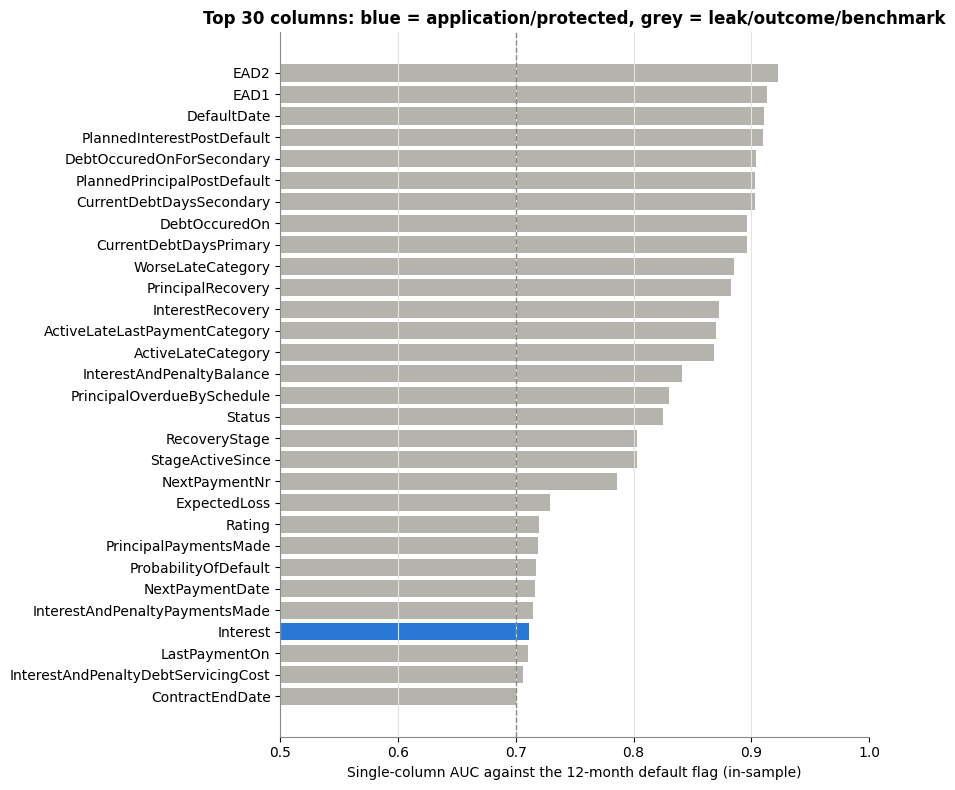

In [30]:
# Bar chart of the 30 strongest columns, coloured by class.
top = screen.dropna(subset=["auc"]).sort_values("auc", ascending=True).tail(30)
fig, ax = plt.subplots(figsize=(9, 8))
colors = [BLUE if c in ("application", "protected") else GREY for c in top["cls"]]
ax.barh(top["column"], top["auc"], color=colors)
ax.axvline(0.70, color="#8a8984", linewidth=1, linestyle="--")   # the suspicion threshold
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Single-column AUC against the 12-month default flag (in-sample)")
ax.set_title("Top 30 columns: blue = application/protected, grey = leak/outcome/benchmark")
ax.grid(axis="x", color="#e4e3df"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### What the result shows
* The screen confirms the classification. The strongest columns are all outcomes or leaks: `EAD2` (0.92), `EAD1`, `DefaultDate`, the 2021 debt and late-payment fields, all around 0.87 to 0.92. They "predict" default because they were recorded after it happened.
* Median AUC by class: outcome 0.88, leak 0.69, application 0.55, protected 0.53. Application columns are individually weak, as expected: a scorecard gets its power from combining many weak signals.
* Bondora's own `ProbabilityOfDefault` scores only 0.72 on its own. That is the benchmark our scorecard will be compared against.
* **One application column is flagged: `Interest` (0.711).** It is known on the application day, so it is not a leak. But Bondora sets the interest rate from its own risk rating, so `Interest` is really Bondora's risk opinion in disguise. `MonthlyPayment` is calculated from the rate, the amount and the term, so it carries the same signal.

### Recommended action
* **D-012:** `Interest` and `MonthlyPayment` are left out of the main (champion) scorecard, so the comparison "our scorecard vs Bondora's PD" stays independent. A second version with both added back shows how much the price adds.
* All columns in the `leak`, `outcome` and `benchmark` classes are excluded from every model matrix (enforced by the registry test in Phase 2).

## Step 5. Structural missingness: which application features exist in which years?

### Why this step
Lenders change their application forms over time: they add questions, drop others, start buying a new credit-bureau score. A model trained on one period and used on another can only use information that exists in both.

This matters a lot here, because the plan trains the scorecard on older loans (development window) and tests it on 2020 to 2021 loans (out-of-time window). If a feature is filled in for 2016 but empty for 2020, the model cannot use it in the test, and worse, a "missing" group would really mean "issued after the form changed", teaching the model the calendar instead of borrower risk.

Bondora uses `-1` for "not collected", so `-1` counts as missing here. The heatmap shows each feature whose missing share changes by more than 20 percentage points across years.

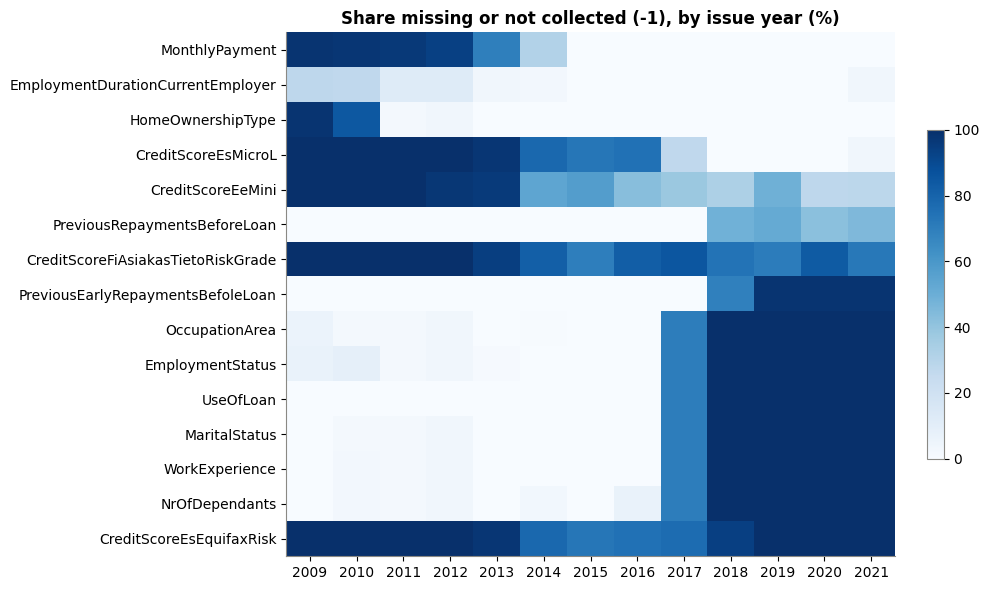

LoanDate,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
MonthlyPayment,98,97,96,93,69,31,0,0,0,0,0,0,0
EmploymentDurationCurrentEmployer,28,27,12,12,3,3,0,0,0,0,0,0,3
HomeOwnershipType,98,84,2,4,0,0,0,0,0,0,0,0,0
CreditScoreEsMicroL,100,100,100,100,98,78,73,75,27,0,0,0,3
CreditScoreEeMini,100,100,100,97,96,54,57,43,38,32,49,27,28
PreviousRepaymentsBeforeLoan,0,0,0,0,0,0,0,0,0,49,52,42,45
CreditScoreFiAsiakasTietoRiskGrade,100,100,100,100,94,82,70,82,86,74,71,83,72
PreviousEarlyRepaymentsBefoleLoan,0,0,0,0,0,0,0,0,0,69,98,98,98
OccupationArea,6,2,2,4,0,1,0,0,70,100,100,100,100
EmploymentStatus,7,9,2,4,1,0,0,0,70,100,100,100,100


In [31]:
# Application and protected columns, except plain dates (they are never missing).
app_cols = [c for c in registry.query("cls in ['application', 'protected']")["column"]
            if c not in ("LoanDate", "LoanApplicationStartedDate", "FirstPaymentDate",
                         "MaturityDate_Original", "DateOfBirth")]
year = pd.to_datetime(df["LoanDate"]).dt.year


def missing_mask(s: pd.Series) -> pd.Series:
    """True where a value is empty, or is Bondora's code -1 for 'not collected'."""
    m = s.isna()
    if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
        m |= s.eq(-1)
    return m


# Share missing per feature and issue year (rows = features, columns = years), in percent.
miss = pd.DataFrame({c: missing_mask(df[c]).astype(float) for c in app_cols}).groupby(year).mean().T * 100
# Keep the features whose missing share moves by more than 20 points from year to year.
changing = miss[(miss.max(axis=1) - miss.min(axis=1)) > 20].sort_values(2019)

fig, ax = plt.subplots(figsize=(10, 0.32 * len(changing) + 1.2))
im = ax.imshow(changing.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(changing.columns)), changing.columns)
ax.set_yticks(range(len(changing.index)), changing.index)
ax.grid(False)
ax.set_title("Share missing or not collected (-1), by issue year (%)")
fig.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout(); plt.show()
changing.round(0).astype(int)

In [32]:
# The exact day the form changed: last loan with EmploymentStatus filled in, first loan without it.
sql("""
SELECT max("LoanDate") FILTER (WHERE "EmploymentStatus" <> -1) AS last_collected,
       min("LoanDate") FILTER (WHERE "EmploymentStatus" = -1)  AS first_not_collected
FROM kaggle_loans
""")

,last_collected,first_not_collected
0,2017-06-02,2017-06-01


### What the result shows
Three different patterns:

* **Six form fields were dropped on 1 June 2017.** `EmploymentStatus`, `MaritalStatus`, `UseOfLoan`, `OccupationArea`, `WorkExperience` and `NrOfDependants` are filled in for almost every loan up to 2 June 2017 and empty for every loan from 2018 on. 2017 is 70% empty because the change happened in the middle of the year.
* **Two previous-loan amounts are missing from 2018.** `PreviousRepaymentsBeforeLoan` is empty for about half the loans from 2018 and `PreviousEarlyRepaymentsBefoleLoan` for nearly all from 2019. The previous-loan *counts* stay filled in.
* **Credit-bureau scores belong to one country each.** `CreditScoreEsMicroL` and `CreditScoreEsEquifaxRisk` are Spanish bureaus, `CreditScoreFiAsiakasTietoRiskGrade` is Finnish, `CreditScoreEeMini` is Estonian. Their missing share mostly follows how many loans come from that country, so they must be judged within their own country.
* Older gaps (`MonthlyPayment` before 2015, `HomeOwnershipType` before 2011) fall before the development window and do not matter.

### Recommended action
* **D-009:** only features filled in for both the development and the out-of-time window are scorecard candidates. The six dropped form fields and the two previous-loan amounts are excluded.
* In Phase 2, check each bureau score within its own country before deciding whether it can be used.

## Step 6. Coded categorical fields

### Why this step
Several Kaggle fields store a category as a number: `Education` 1 to 5 (from primary to higher education), `HomeOwnershipType` 0 to 10 (owner, tenant, living with parents...). The Bondora dataset dictionary lists the valid codes. A code outside the list is a data error, and it has to be handled before the codes are turned into labels at staging.

In [33]:
# Valid codes per field, from the Bondora dataset dictionary.
CODE_RANGES = {
    "Education": range(1, 6), "EmploymentStatus": range(1, 7), "MaritalStatus": range(1, 6),
    "HomeOwnershipType": range(0, 11), "VerificationType": range(1, 5), "Gender": range(0, 3),
    "OccupationArea": range(1, 20),
    "UseOfLoan": [*range(0, 9), *range(101, 111)],
}
codes = []
for col, valid in CODE_RANGES.items():
    s = df[col]
    is_invalid = ~s.isin(list(valid)) & s.ne(-1) & s.notna()   # not valid, not -1, not empty
    codes.append({
        "column": col, "valid_codes": f"{min(valid)}..{max(valid)}",
        "not_collected_-1": int(s.eq(-1).sum()), "null": int(s.isna().sum()),
        "invalid": int(is_invalid.sum()),
        "invalid_values": sorted(s[is_invalid].unique().tolist()),
    })
pd.DataFrame(codes)

,column,valid_codes,not_collected_-1,null,invalid,invalid_values
0,Education,1..5,729,50,8,[0.0]
1,EmploymentStatus,1..6,142647,202,32,[0.0]
2,MaritalStatus,1..5,142647,50,8,[0.0]
3,HomeOwnershipType,0..10,3,1657,0,[]
4,VerificationType,1..4,0,50,8,[0.0]
5,Gender,0..2,0,45,0,[]
6,OccupationArea,1..19,142698,91,11,[0.0]
7,UseOfLoan,0..110,142647,0,0,[]


### What the result shows
* Every invalid value is `0`, on only 8 to 32 loans per field (in five fields). For `VerificationType` the dictionary itself calls `0` "not set".
* The large `-1` counts (142,647 loans) are the dropped form fields from step 5, not errors.
* `HomeOwnershipType` has 1,657 empty values, mostly from the earliest years.

### Recommended action
* At staging, map code `0` (where it is not a valid code) and empty values to an explicit `Unknown` group instead of dropping the loans. A scorecard can give "unknown" its own score.
* Use the dictionary's labels (for example `Education` 4 = "Secondary") at staging so tables and charts read in words, not codes.

## Step 7. Kaggle status in 2021 vs official status today

### Why this step
The Kaggle file has a `Status` column (`Current`, `Late`, `Repaid`). It is tempting to use it as the target. But it describes each loan on 20 July 2021 only. The official feed shows where the same loans ended up by 2026. Comparing the two shows how much happened after the snapshot, and so whether `Status` could be trusted as an outcome.

In [34]:
# Count loans for every combination of 2021 Kaggle status and current official status.
status = sql("""
SELECT "Status" AS kaggle_status_2021, off_loan_status AS official_status_now, count(*) AS loans
FROM loans GROUP BY ALL ORDER BY loans DESC
""")
# Reshape into a cross-table: rows = 2021 status, columns = status now.
status.pivot(index="kaggle_status_2021", columns="official_status_now", values="loans").fillna(0).astype(int)

official_status_now,Active,Defaulted,Repaid
kaggle_status_2021,,,
Current,9313,10870,37591
Late,620,25440,42514
Repaid,0,0,52887


### What the result shows
* **10,870 loans that were `Current` (paying normally) in 2021 have defaulted since.** A model trained on Kaggle `Status` would have called them good.
* Of the loans that were `Late` in 2021, 42,514 were eventually repaid and 25,440 defaulted. "Late" is a temporary state, not an outcome.
* Every loan `Repaid` in 2021 is still `Repaid`, as it should be.

### Recommended action
* The target comes from the official feed (`has_default_within_12_months`), never from Kaggle `Status`.
* Kaggle `Status` stays classified as `outcome`, used only for cross-checks.

## Step 8. The official target and the loan status

### Why this step
Before building samples we need to understand exactly what the target values mean for each kind of loan. Notebook 01 reported "no missing target among mature loans". This cross-table checks whether every 0 really means "did not default".

In [35]:
# Every combination of loan status, 12-month flag and overall default flag, with its loan count.
sql("""
SELECT loan_status, has_default_within_12_months AS default_12m, is_default, count(*) AS loans
FROM official_loans GROUP BY ALL ORDER BY loan_status, default_12m, is_default
""")

,loan_status,default_12m,is_default,loans
0,Active,0.0,0.0,188388
1,Active,1.0,0.0,198
2,Active,NaN,0.0,149876
3,Defaulted,0.0,1.0,63872
4,Defaulted,1.0,1.0,45904
5,Defaulted,NaN,1.0,5220
6,InPostFundingReview,0.0,NaN,11
7,Repaid,0.0,0.0,304454
8,Repaid,0.0,1.0,557
9,Repaid,0.0,NaN,3460


### What the result shows
* **`Returned` (4,241 loans) and `InPostFundingReview` (11 loans) all have `default_12m = 0`.** These loans were cancelled or never funded normally. Their 0 means "nothing was observed", not "the borrower repaid". Notebook 01 counted them as valid non-defaults.
* **About 44,500 loans are `Repaid` but have `default_12m = 1`.** These are *cured* defaults: the borrower defaulted in the first year and later paid everything back. For a 12-month PD they are correctly bads, because the default happened.
* **About 64,000 loans are `Defaulted` but have `default_12m = 0`.** They defaulted after month 12. For the 12-month scorecard they are goods; for the lifetime PD used in IFRS 9 (Phase 5) they are bads.

### Recommended action
* **D-010:** exclude `Returned` and `InPostFundingReview` loans as the first step of the exclusions waterfall in Phase 2, and show their count in the waterfall table.
* Keep cured defaults as bads. Remember that the 12-month target and the lifetime default are different things.

## Step 9. Target reconciliation: official flag vs Kaggle `DefaultDate`

### Why this step
The target is the most important column in the project, so we confirm it with a second, independent source. The Kaggle file has a `DefaultDate` for each defaulted loan. If that date falls within 12 months of the loan start, Kaggle also says "defaulted within 12 months". Measuring how often the two sources agree tells us how much to trust the target. This *agreement rate* goes in the data card.

A Kaggle loan can only show a 12-month default if it was at least 12 months old on 20 July 2021, so we compare only loans issued on or before 20 July 2020.

In [36]:
# For each comparable loan: issue year, the official 12-month flag, and the same flag rebuilt from Kaggle.
recon = sql(f"""
SELECT year("LoanDate") AS issue_year,
       off_has_default_within_12_months::INT AS official_12m,
       ("DefaultDate" IS NOT NULL AND "DefaultDate" < "LoanDate" + INTERVAL 12 MONTH)::INT AS kaggle_12m
FROM loans
WHERE "LoanDate" <= DATE '{KAGGLE_ASOF}' - INTERVAL 12 MONTH
  AND off_has_default_within_12_months IS NOT NULL
""")
agreement = (recon["official_12m"] == recon["kaggle_12m"]).mean()
print(f"Loans compared: {len(recon):,}   Agreement: {agreement:.2%}")
# Cross-table of the two flags; "All" gives the totals.
pd.crosstab(recon["kaggle_12m"], recon["official_12m"], margins=True,
            rownames=["Kaggle DefaultDate within 12m"], colnames=["Official flag"])

Loans compared: 148,783   Agreement: 99.69%


Official flag,0,1,All
Kaggle DefaultDate within 12m,,,
0,105328,454,105782
1,0,43001,43001
All,105328,43455,148783


In [37]:
# The same comparison per issue year, with each source's default rate.
by_year = recon.assign(agree=recon["official_12m"] == recon["kaggle_12m"]).groupby("issue_year").agg(
    loans=("agree", "size"), agreement_pct=("agree", "mean"),
    official_dr_pct=("official_12m", "mean"), kaggle_dr_pct=("kaggle_12m", "mean"))
by_year[["agreement_pct", "official_dr_pct", "kaggle_dr_pct"]] *= 100
by_year.round(2)

,loans,agreement_pct,official_dr_pct,kaggle_dr_pct
issue_year,,,,
2009,665,93.38,33.83,27.22
2010,1157,96.72,26.88,23.60
2011,451,98.67,15.08,13.75
2012,457,98.03,9.19,7.22
2013,2512,98.21,13.38,11.58
2014,7455,99.26,29.08,28.34
2015,8046,99.58,32.56,32.14
2016,10514,99.55,34.90,34.45
2017,17933,99.79,36.65,36.44


### What the result shows
* On 148,783 comparable loans the two sources agree **99.69%** of the time.
* All 454 disagreements go the same way: the official feed records a 12-month default that the 2021 Kaggle file does not. There is not a single loan that Kaggle calls a 12-month default and the official feed does not. The official flag is the more complete of the two.
* Agreement is lower for 2009 to 2013 (93% to 98%), when Bondora's processes were young and loan numbers small, and above 99.5% from 2015 on, which covers the years we model.

### Recommended action
* Keep the official flag as the target, as planned.
* Report the 99.69% agreement rate, and the fact that the disagreements are one-directional, in `docs/data_card.md`.

## Step 10. Which official field marks the default month?

### Why this step
Track B (IFRS 9) needs more than "did the loan default within 12 months". It needs **when** each loan defaulted, to build *vintage curves*: for every group of loans issued in the same quarter, the share that has defaulted after 1, 2, 3... months on book. These curves give the lifetime PD used for expected-loss provisions.

The official feed has no column called "default date", so three candidates are tested against the Kaggle `DefaultDate`, on loans that had already defaulted by 2021 (so the Kaggle date is final) and are `Defaulted` in the official feed:

1. `debt_occured_date_local`: the date the borrower first fell behind (the data dictionary warns that it changes over time).
2. Feed date minus `months_in_default`: count back from today by the months the loan has been in default.
3. Issue date plus `months_on_book`: count forward from the issue date by the months the loan was on the books.

In [38]:
cand = sql(f"""
WITH d AS (
    -- One row per loan defaulted in both sources, with the inputs of the three candidates.
    SELECT "LoanDate" AS issue_date, "DefaultDate" AS kaggle_default,
           CASE WHEN year(off_debt_occured_date_local) = 1970 THEN NULL      -- drop placeholders (step 3)
                ELSE off_debt_occured_date_local::DATE END AS debt_date,
           off_months_on_book AS mob, off_months_in_default AS mid
    FROM loans
    WHERE "DefaultDate" IS NOT NULL AND off_loan_status = 'Defaulted'
)
-- For each candidate: share landing in the same month as the Kaggle default, and within one month.
SELECT 'debt_occured_date_local' AS candidate,
       count(debt_date) AS loans,
       avg((date_diff('month', kaggle_default, debt_date) = 0)::INT) AS same_month,
       avg((abs(date_diff('month', kaggle_default, debt_date)) <= 1)::INT) AS within_1_month
FROM d
UNION ALL
SELECT 'feed_date - months_in_default', count(mid),
       avg((date_diff('month', kaggle_default, DATE '{FEED_DATE}') = mid)::INT),
       avg((abs(date_diff('month', kaggle_default, DATE '{FEED_DATE}') - mid) <= 1)::INT)
FROM d
UNION ALL
SELECT 'issue_date + months_on_book', count(mob),
       avg((date_diff('month', issue_date, kaggle_default) = mob)::INT),
       avg((abs(date_diff('month', issue_date, kaggle_default) - mob) <= 1)::INT)
FROM d
""")
cand[["same_month", "within_1_month"]] = (cand[["same_month", "within_1_month"]] * 100).round(1)
cand

,candidate,loans,same_month,within_1_month
0,debt_occured_date_local,22083,13.6,19.0
1,feed_date - months_in_default,23725,28.7,99.9
2,issue_date + months_on_book,23725,64.4,99.7


In [39]:
# How many days after the first missed payment does Bondora mark the default?
gap = sql("""
SELECT date_diff('day', off_debt_occured_date_local::DATE, "DefaultDate") AS days
FROM loans
WHERE "DefaultDate" IS NOT NULL AND off_loan_status = 'Defaulted'
  AND year(off_debt_occured_date_local) <> 1970
""")["days"]
print("Days from debt_occured_date to Kaggle DefaultDate, quantiles:")
print(gap.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).to_string())

Days from debt_occured_date to Kaggle DefaultDate, quantiles:
0.05      0.0
0.25     63.0
0.50     78.0
0.75     92.0
0.95    125.0


### What the result shows
* **`debt_occured_date_local` is the wrong event.** It matches the default month for only 14% of loans, because it marks the *start* of the arrears. The default follows a median of 78 days later (half of loans between 63 and 92 days), which fits a default rule of about 60 days past due plus processing time.
* **Feed date minus `months_in_default`** is within one month for 99.9% of loans but in the exact month for only 29%. The count runs to an unstated extraction date (around 22 October 2026), so the exact month depends on a date we would have to guess.
* **Issue date plus `months_on_book`** is in the exact month for 64% of loans and within one month for 99.7%. For defaulted loans, `months_on_book` stops counting at default, and this candidate needs no reference date at all.

### Recommended action
* **D-011:** in `mart_vintage_curves`, default month = issue month + `months_on_book`, for loans with status `Defaulted`.
* Do not use `debt_occured_date_local` as a default date.

## Step 11. Summary of findings and recommended actions

### Findings

| # | Area | Finding | Recommended action | Decision |
|---|---|---|---|---|
| 1 | Provenance | The warehouse matches the fingerprinted raw files; no duplicate IDs; every Kaggle loan joins. One loan disagrees on country. | None; rebuild the warehouse if the check ever fails. | D-007 |
| 2 | Data quality | No error rule fails. Warnings: 53 impossible ages (0 to 2), 64 zero incomes, a few odd official balances and rates. | Fix at staging (impossible age to missing, flag zero income); list in the data card. | |
| 3 | Placeholder dates | Four official date columns use 1 January 1970 for empty values (15,379 to 25,216 loans each). | Convert to NULL in `stg_official_loans`; add a test. | |
| 4 | Column registry | All 112 Kaggle columns classified; 27 classified in this audit. 38 columns are leaks. | Write `config/feature_registry.yaml` and a test that blocks non-application columns from models. | Phase 2 |
| 5 | Leakage screen | Outcome and leak columns reach AUC 0.87 to 0.92 alone, confirming they must stay out. `Interest` (0.71) carries Bondora's own risk view. | Leave `Interest` and `MonthlyPayment` out of the champion; test them in a sensitivity version. | D-012 |
| 6 | Feature availability | Six form fields stopped on 1 June 2017; two previous-loan amounts missing from 2018; bureau scores are country-specific. | Use only features filled in for both the development and out-of-time windows; check bureau scores within country. | D-009 |
| 7 | Coded fields | Code `0` appears in five fields where it is not valid (8 to 32 loans each). | Map to `Unknown` at staging. | |
| 8 | Kaggle status | 10,870 loans "Current" in 2021 have defaulted since. | Never use Kaggle `Status` as a target. | |
| 9 | Target meaning | Returned and InPostFundingReview loans have a 0 that means "not observed". | Exclude them first in the waterfall. | D-010 |
| 10 | Target reconciliation | Official flag and Kaggle default date agree on 99.69% of 148,783 loans; all disagreements are defaults only the official feed recorded. | Keep the official target; report the rate in the data card. | |
| 11 | Default month | Issue month + `months_on_book` matches the Kaggle default month within one month for 99.7% of loans. | Use it in `mart_vintage_curves`. | D-011 |
| 12 | Slovakia | Only 296 Slovak loans (from notebook 01 and the warehouse). | Keep in the data, no separate reporting. | D-008 |

### What this means for the next phase

The data are fit for modelling once the staging fixes above are made. Phase 2 starts with:

1. `config/feature_registry.yaml` built from the registry table in step 4, applying D-009 and D-012, with its test.
2. The exclusions waterfall: Returned and InPostFundingReview loans first (D-010), then the remaining exclusions from the roadmap, showing the loan count and default rate after each step.
3. `docs/data_card.md`: sources, fingerprints, row counts, the known issues from steps 2, 3 and 6, and the 99.69% target agreement.

### The audit in one paragraph (for my  video)

Before building any model, I checked the data the way a bank's validation team would. The warehouse matches the exact files I downloaded, and the data pass every hard quality rule. Going through all 112 columns showed that 38 of them describe what happened after the loan was paid out; they predict default almost perfectly, which is exactly why they must stay out of the model. The interest rate is Bondora's own risk opinion, so I keep it out to make the comparison with Bondora's model fair. Bondora changed its application form in June 2017, so some questions only exist for older loans and cannot be used. Finally, I confirmed the target with a second source: the official default flag and the Kaggle default dates agree on 99.7% of loans.

In [40]:
con.close()   # release the warehouse file